# Final model: a 4.84M-parameter Wide ResNet distilled from an ensemble

NYU Tandon Deep Learning, Fall 2026, Project 1 (Kaggle: *cifar-10-res-net-architecture-challenge-dl*).

This notebook
1. builds the architecture and prints its parameter count (limit: 5,000,000),
2. loads the trained weights of the submitted model (`k25f`),
3. measures its accuracy on the official CIFAR-10 test set: 10,000 labelled images that no model in this
   project was trained on,
4. predicts the hidden Kaggle test set and writes `submission.csv`.

Training takes hours, so it runs from the command line (`python train.py --config ...`, see the README); the
training logs of every experiment are plotted in `experiments.ipynb`, and the depth vs width study is in
`depth_width.ipynb`.

In [1]:
import os
import sys
from pathlib import Path

for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_var, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display

print(f"torch {torch.__version__}, GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}")

torch 2.14.1+cu130, GPU: NVIDIA RTX A3000 Laptop GPU


In [2]:
# Chart style: hairline grid and axes, 2px lines, fixed categorical colour order.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"], "font.size": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "text.color": INK,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
    "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
})
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

In [3]:
from resnet5m.data import CLASSES, GpuNormalize, load_cifar10_test, load_test_images
from resnet5m.inference import load_model, predict_probs
from resnet5m.models import PARAM_LIMIT, build_model, count_params

FINAL = "k25f_kd_ens4t4t5_T4_3200ep_full"  # the submitted model: trained on all 50,000 training images
RUNNERS_UP = ["k20f_kd_ens4t4_T4_3200ep_full", "k22f_kd_ens4t4_T4_6400ep_full"]  # same recipe, other teachers / length
KAGGLE = {"public": None, "private": None}  # hidden-test accuracy reported by Kaggle (fill in; private after the deadline)

## 1. Architecture and parameter count

A pre-activation Wide ResNet (Zagoruyko & Komodakis, 2016) with 28 layers: a 3x3 stem convolution, three
stages of four residual blocks with 64, 128 and 224 channels, then global average pooling and a linear
classifier. Each block computes `y = S(x) + F(x)`, where `F` is BN-ReLU-conv3x3-BN-ReLU-conv3x3 and `S` is
the identity, or a 1x1 convolution where the shape changes (first block of each stage). Stages 2 and 3
halve the resolution with a stride-2 first block.

In [4]:
cfg = yaml.safe_load(open(f"runs/{FINAL}/config.yaml"))
model_cfg = dict(cfg["model"])
model = build_model(model_cfg.pop("name"), **model_cfg)


def n_params(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)


n = len(model.blocks) // 3
size = 32
rows = [("stem: 3x3 convolution", 3, model.stem.out_channels, "32x32", n_params(model.stem))]
for i in range(3):
    stage = model.blocks[i * n:(i + 1) * n]
    size //= stage[0].conv1.stride[0]
    rows.append((f"stage {i + 1}: {n} residual blocks", stage[0].conv1.in_channels, stage[-1].conv2.out_channels,
                 f"{size}x{size}", n_params(stage)))
rows.append(("BN-ReLU, global average pool, linear", model.fc.in_features, model.fc.out_features, "1x1",
             n_params(model.bn) + n_params(model.fc)))
layers = pd.DataFrame(rows, columns=["layer", "in channels", "out channels", "output size", "parameters"])
total = count_params(model)
assert total == layers["parameters"].sum()
display(layers.assign(parameters=layers["parameters"].map("{:,}".format)))
print(f"Total trainable parameters: {total:,} (limit {PARAM_LIMIT:,}, {total / PARAM_LIMIT:.1%} of the budget)")
assert total <= PARAM_LIMIT

,layer,in channels,out channels,output size,parameters
0,stem: 3x3 convolution,3,16,32x32,432
1,stage 1: 4 residual blocks,16,64,32x32,"269,216"
2,stage 2: 4 residual blocks,64,128,16x16,"1,116,032"
3,stage 3: 4 residual blocks,128,224,8x8,"3,451,200"
4,"BN-ReLU, global average pool, linear",224,10,1x1,"2,698"


Total trainable parameters: 4,839,578 (limit 5,000,000, 96.8% of the budget)


In [5]:
print(model.blocks[n])  # the first block of stage 2: stride 2 and a 1x1 projection shortcut

PreActBlock(
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (dropout): Identity()
  (se): Identity()
  (bn3): Identity()
  (reg): Identity()
  (shortcut): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
)


## 2. The trained model

Recipe (`configs/kd_wrn28_from_t1.yaml` with the overrides in `queues/hpc9.txt`): SGD with Nesterov momentum 0.9
(batch 128, peak lr 0.1 after a 5-epoch warmup, cosine decay to 0 over 3,200 epochs, weight decay 5e-4 except on
BN and biases); random crop + flip, TrivialAugment, Cutout and CutMix/MixUp on every batch; an exponential moving
average of the weights (decay 0.9995) is the final model. The loss is 90% knowledge distillation (temperature 4)
and 10% cross-entropy with the (mixed) labels. The teacher labels exactly the augmented, mixed image the student
sees ("function matching", Beyer et al., 2022).

The teachers are six of our own models, all trained from scratch on the competition's training images only:
four 4.84M-parameter WRN-28s (`s3`, `s4`, `s5`, `k4`) and two WRN-28-10s (36.5M parameters, 800 epochs; `t4` on
45,000 images, `t5f` on all 50,000). The teachers exceed the 5M limit and are not submitted; only the student is.

In [6]:
ckpt = torch.load(f"runs/{FINAL}/model_final.pt", map_location="cpu", weights_only=False)
s = ckpt["summary"]
print(f"{FINAL}: {ckpt['params']:,} trainable parameters")
print(f"trained for {s['epochs']} epochs ({s['train_hours']:.1f} GPU-hours on one A100) on all 50,000 training images")
print("teachers:", [Path(t).parent.name for t in cfg["kd"]["teachers"]], f"temperature {cfg['kd']['temperature']}")

k25f_kd_ens4t4t5_T4_3200ep_full: 4,839,578 trainable parameters
trained for 3200 epochs (12.7 GPU-hours on one A100) on all 50,000 training images
teachers: ['s3_wrn28_800ep', 's4_wrn28_1600ep', 's5_wrn28_800ep_seed1', 'k4_kd_s3_T4_800ep', 't4_wrn28_10_800ep_seed1', 't5f_wrn28_10_800ep_seed2_full'] temperature 4.0


## 3. Accuracy on held-out labelled images: the CIFAR-10 test set

The submitted model saw all 50,000 training images, so it is measured on the official CIFAR-10 test batch:
10,000 labelled images (1,000 per class) that were never used for training or for any teacher. Test-time
augmentation (TTA) averages the softmax over views: `flip` adds the mirror image, `flip_shift` also 1-pixel
diagonal shifts (6 views). The two runners-up (same recipe, other teachers or schedule length) are shown from
their saved evaluations; differences of 0.1 points (10 images) between them are within noise.

In [7]:
images, labels = load_cifar10_test("data")
xt, yt = torch.from_numpy(images).cuda(), torch.from_numpy(labels).cuda()
norm = GpuNormalize("cuda")

final, ckpt = load_model(f"runs/{FINAL}/model_final.pt")
test_probs10k, row = {}, {"run": FINAL}
for tta in ("none", "flip", "flip_shift"):
    p = predict_probs(final, xt, norm, tta)
    test_probs10k[tta] = p.cpu().numpy()
    row[f"TTA {tta}"] = (p.argmax(1) == yt).float().mean().item() * 100
rows = [row]
for run in RUNNERS_UP:  # recorded by scripts/eval_cifar10_test.py on the cluster
    saved = json.load(open(f"runs/{run}/cifar10_test.json"))
    rows.append({"run": run, **{f"TTA {t}": 100 * saved[t] for t in ("none", "flip", "flip_shift")}})
test_table = pd.DataFrame(rows).set_index("run")
display(test_table.round(2))
acc = test_table.loc[FINAL, "TTA flip_shift"]
print(f"CIFAR-10 test accuracy of the final model (10,000 images, flip_shift TTA): {acc:.2f}%")

,TTA none,TTA flip,TTA flip_shift
run,,,
k25f_kd_ens4t4t5_T4_3200ep_full,98.09,98.13,98.16
k20f_kd_ens4t4_T4_3200ep_full,98.04,98.20,98.14
k22f_kd_ens4t4_T4_6400ep_full,98.13,98.07,98.14


CIFAR-10 test accuracy of the final model (10,000 images, flip_shift TTA): 98.16%


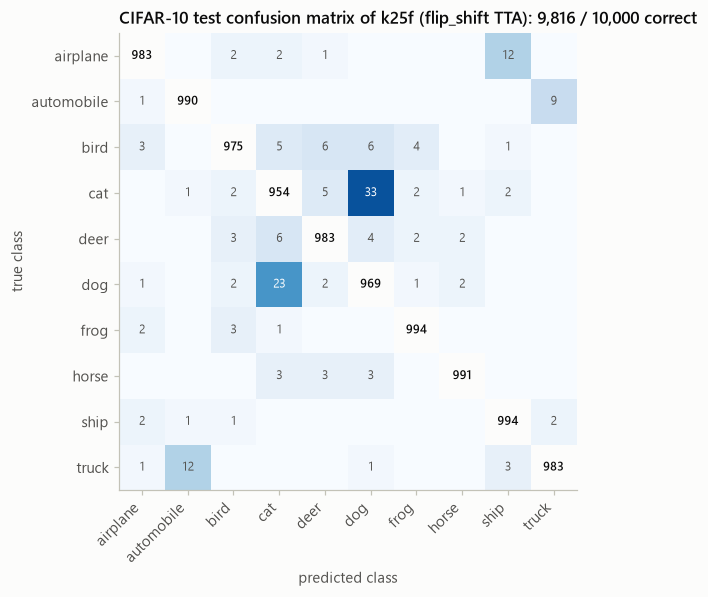

most frequent errors: {'cat -> dog': 33, 'dog -> cat': 23, 'airplane -> ship': 12, 'truck -> automobile': 12, 'automobile -> truck': 9}
per-class accuracy (%): {'airplane': 98.3, 'automobile': 99.0, 'bird': 97.5, 'cat': 95.4, 'deer': 98.3, 'dog': 96.9, 'frog': 99.4, 'horse': 99.1, 'ship': 99.4, 'truck': 98.3}


In [8]:
pred = test_probs10k["flip_shift"].argmax(1)
y = labels
cm = np.zeros((10, 10), int)
np.add.at(cm, (y, pred), 1)

fig, ax = plt.subplots(figsize=(6.2, 5.4))
off = cm.astype(float)
np.fill_diagonal(off, np.nan)  # colour only the errors; the diagonal (correct) is printed in ink
ax.imshow(off, cmap="Blues", vmin=0, vmax=np.nanmax(off) * 1.15)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            dark = i != j and cm[i, j] > np.nanmax(off) * 0.6
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="#ffffff" if dark else (INK if i == j else INK2), weight="semibold" if i == j else None)
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10), CLASSES)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.grid(False)
ax.set_title(f"CIFAR-10 test confusion matrix of {FINAL.split('_')[0]} (flip_shift TTA): "
             f"{np.trace(cm):,} / {cm.sum():,} correct")
fig.savefig(FIG_DIR / "confusion_matrix.png")
plt.show()
errors = pd.Series({f"{CLASSES[i]} -> {CLASSES[j]}": cm[i, j] for i in range(10) for j in range(10) if i != j})
print("most frequent errors:", errors.sort_values(ascending=False).head(5).to_dict())
per_class = pd.Series(np.diag(cm) / cm.sum(1) * 100, index=CLASSES).round(1)
print("per-class accuracy (%):", per_class.to_dict())

## 4. Hidden test set: predictions and submission file

The 2,000 hidden test images (`data/kaggle/test_images`, ids from `test.csv`) are only ever used to write
predictions: no test-time adaptation, no labels.

In [9]:
ids, test_images = load_test_images("data")
test_probs = predict_probs(final, torch.from_numpy(test_images).cuda(), norm, "flip_shift").cpu().numpy()
test_pred = test_probs.argmax(1)
submission = pd.DataFrame({"id": ids, "label": test_pred})
sample = pd.read_csv("data/kaggle/sample_submission.csv")
assert (submission["id"].to_numpy() == sample["id"].to_numpy()).all() and len(submission) == len(sample)
submission.to_csv("submission.csv", index=False)
print(f"wrote submission.csv: {len(submission)} predictions")
submitted = Path(f"submissions/{FINAL}_flipshift.csv")
if submitted.exists():
    same = (pd.read_csv(submitted)["label"].to_numpy() == test_pred).mean()
    print(f"agreement with the file submitted to Kaggle: {same:.2%}")

wrote submission.csv: 2000 predictions
agreement with the file submitted to Kaggle: 99.95%


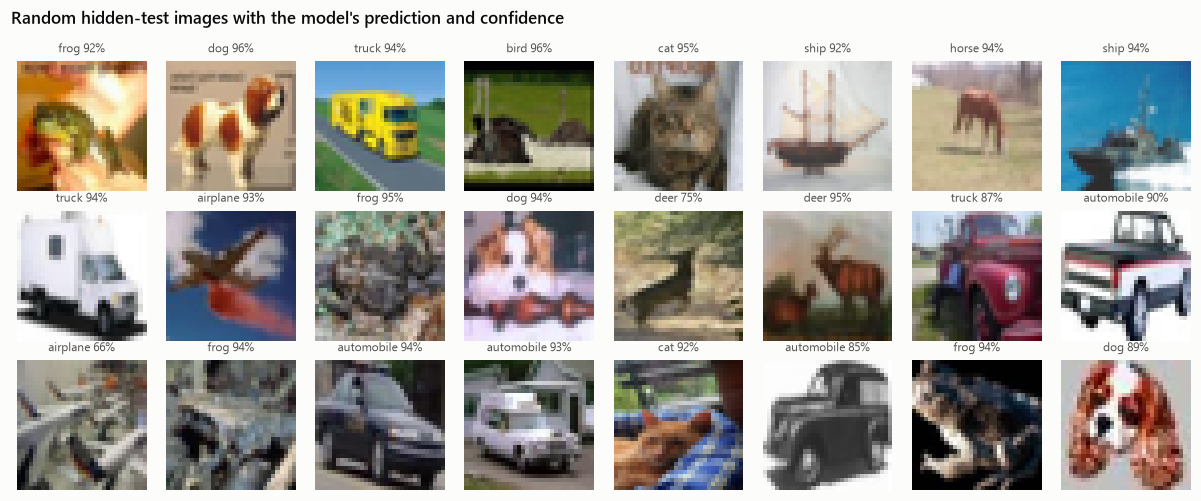

In [10]:
rng = np.random.default_rng(0)
show = rng.choice(len(ids), 24, replace=False)
fig, axes = plt.subplots(3, 8, figsize=(11, 4.6))
for ax, i in zip(axes.flat, show):
    ax.imshow(test_images[i].transpose(1, 2, 0), interpolation="nearest")
    ax.set_title(f"{CLASSES[test_pred[i]]} {test_probs[i].max():.0%}", fontsize=8, loc="center",
                 color=INK2, weight="normal")
    ax.axis("off")
fig.suptitle("Random hidden-test images with the model's prediction and confidence", x=0.01, ha="left",
             fontsize=11, weight="semibold")
fig.tight_layout()
fig.savefig(FIG_DIR / "test_predictions.png")
plt.show()

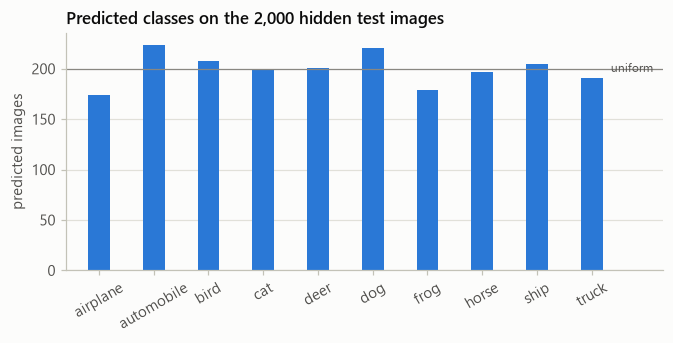

{'airplane': 174, 'automobile': 224, 'bird': 208, 'cat': 200, 'deer': 201, 'dog': 221, 'frog': 179, 'horse': 197, 'ship': 205, 'truck': 191}


In [11]:
counts = np.bincount(test_pred, minlength=10)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(CLASSES, counts, width=0.4, color=BLUE)
ax.axhline(len(test_pred) / 10, color=MUTED, lw=0.8)
ax.set_xlim(-0.6, 10.3)
ax.text(9.35, len(test_pred) / 10, "uniform", va="center", fontsize=8, color=INK2)
ax.set_ylabel("predicted images")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="x", visible=False)
ax.set_title("Predicted classes on the 2,000 hidden test images")
fig.savefig(FIG_DIR / "test_class_counts.png")
plt.show()
print(dict(zip(CLASSES, counts.tolist())))

## 5. Final numbers

In [12]:
print(f"Model: pre-activation WRN-28, widths {cfg['model']['widths']}, {count_params(final):,} trainable parameters "
      f"(limit {PARAM_LIMIT:,})")
print(f"Test accuracy on the CIFAR-10 test set (10,000 held-out labelled images, flip_shift TTA): {acc:.2f}%")
fmt = lambda v, later: later if v is None else f"{v:.1%}"
print(f"Kaggle hidden test set: public {fmt(KAGGLE['public'], 'not recorded yet')}, "
      f"private {fmt(KAGGLE['private'], 'available after the competition ends')}")

Model: pre-activation WRN-28, widths [64, 128, 224], 4,839,578 trainable parameters (limit 5,000,000)
Test accuracy on the CIFAR-10 test set (10,000 held-out labelled images, flip_shift TTA): 98.16%
Kaggle hidden test set: public not recorded yet, private available after the competition ends
